<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/09_monthly_retraining_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 09 · Monthly retraining exploration

**Question:** as new labelled applications become available, does updating the model improve future-month performance, or is updating its decision threshold sufficient?

Compare three policies using the same three-seed RUS CatBoost averaging recipe:

1. **Frozen:** retain the initial model and initial calibration cutoff.
2. **Threshold only:** retain the initial model but recalculate its cutoff on the latest labelled month.
3. **Retrain + threshold:** expand the model's training history each month and recalculate its cutoff on the latest labelled month.

Use evaluation months **3, 4 and 5**, exclusively within the development period. Months 6–7 are excluded from loading. All policies share the same initial model and cutoff at month 3. There is no new hyperparameter search, ensemble-weight search or selection of a winning seed.

**Important interpretation:** the CatBoost configuration and ensemble recipe were chosen through earlier month-5 experiments. These are therefore retrospective development backtests, not unbiased historical deployment estimates. Fits and cutoffs respect each simulated time boundary, but configuration selection was not nested within those boundaries. Do not present these results as an untouched test.

This notebook explores the operational update policy; it does not declare modelling complete.


## 1. Timeline and label-availability assumption

Assume all labels from the preceding month are available before scoring the next month. BAF does not provide label-resolution timestamps, so this is an explicit simulation assumption, not a verified banking process. A real fraud-investigation delay could require a longer gap.

Reserve the most recent labelled month for calibration. Do not refit the fraud model on that calibration month after selecting its cutoff, because doing so changes the model whose scores were calibrated.

| Evaluation month | Frozen model: fit / calibrate | Threshold only: fit / calibrate | Retrain + threshold: fit / calibrate |
|---|---|---|---|
| 3 | 0–1 / 2 | 0–1 / 2 | 0–1 / 2 |
| 4 | 0–1 / 2 | 0–1 / 3 | 0–2 / 3 |
| 5 | 0–1 / 2 | 0–1 / 4 | 0–3 / 4 |

This updates the earlier illustrative schedule: we use development months and assume preceding-month label availability. We are **not** simulating a one-month unresolved-label delay. The training cutoff is two months behind evaluation because the latest labelled month is held out for calibration.

At month 5, the refreshed model is intentionally trained only through month 3. Its score must not be compared as an equal-training-data replacement for notebook 08's model trained through month 4.

**What each comparison means:**

- Threshold only minus frozen: the effect of threshold maintenance with identical scores.
- Retrain + threshold minus threshold only: the effect of refreshing the model under the same calibration policy.
- Retrain + threshold minus frozen: the overall effect of the update policy.

Expanding history adds both newer information and more rows. This notebook measures the combined operational effect; it does not isolate recency from sample size (the separate composition studies address that).


## 2. Paths

Colab: reuse `MyDrive/BT4012_grp_proj/processed/baf_clean.parquet` and `preparation_manifest.json`.

Local: put this notebook under `notebooks/` and the prepared files under `data/processed/`. Set `LOCAL_REPO_ROOT` if auto-detection fails.

No saved models or predictions from notebooks 05–08 are required. Those models used later training information and cannot be substituted into the earlier backtest months. This notebook makes nine CatBoost fits: three seeds at each of three training origins.


In [1]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 3. Dependencies and fixed setup

Use the same CatBoost settings as the previous exploration: depth 4, 600 iterations, learning rate 0.05, L2 regularisation 3, 10 legitimate training applications per fraud, equal prediction weights across seeds 42/43/44.

The ensemble is the predictor under evaluation. These seeds are ensemble members, not three independent policy backtests. The target calibration FPR is 5%; also examine exact review capacity at 1%, 2% and 5%.


In [2]:
import importlib.util
import subprocess

required_packages = {'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn',
                     'matplotlib': 'matplotlib', 'joblib': 'joblib',
                     'pyarrow': 'pyarrow>=14', 'catboost': 'catboost>=1.2'}
missing = [package for module, package in required_packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    else:
        raise ImportError('Install into this kernel: python -m pip install ' + ' '.join(missing))

import hashlib
import json
import platform
import time
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import catboost
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEEDS = [42, 43, 44]
N_JOBS = 2
VERIFY_CHECKSUM = True
SAVE_MODELS = True
EVALUATION_MONTHS = [3, 4, 5]
INITIAL_TRAIN_MONTHS = [0, 1]
INITIAL_CALIBRATION_MONTH = 2
FRAUD_PARAMS = {'iterations': 600, 'depth': 4}
NEGATIVES_PER_POSITIVE = 10
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]
POLICIES = ['frozen', 'threshold_only', 'retrain_and_threshold']

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RESULTS_DIR = PROJECT_DIR / 'results' / 'monthly_retraining' / run_id
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'monthly_retraining' / run_id
FIGURES_DIR = RESULTS_DIR / 'figures'
for directory in [RESULTS_DIR, ARTIFACTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200})
print('Planned model fits: 9; no hyperparameter search.')
print('Results:', RESULTS_DIR)


Planned model fits: 9; no hyperparameter search.
Results: /content/drive/MyDrive/BT4012_grp_proj/results/monthly_retraining/20261117T155430Z_2496ed


## 4. Load only development months

Verify provenance and the prepared schema. Numeric missing-value decoding and constant-column exclusion remain exactly as specified by the preparation manifest. All model predictors exclude month, target and row ID.


In [3]:
def file_sha256(path):
    """Verify a prepared input or saved artifact using a chunked digest."""
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run data preparation first with these project paths.')
manifest = json.loads(MANIFEST_PATH.read_text())
assert manifest['schema_version'] == 1
if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Prepared parquet checksum does not match its manifest.')
TARGET, MONTH, ROW_ID = manifest['target'], manifest['month_column'], manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL, CATEGORICAL = manifest['numerical_features'], manifest['categorical_features']
assert set(FEATURES) == set(NUMERICAL + CATEGORICAL)
assert not set(FEATURES) & {TARGET, MONTH, ROW_ID}
assert manifest['split_months']['train'] == [0, 1, 2, 3, 4]
assert manifest['split_months']['validation'] == [5]

development = pd.read_parquet(CLEAN_PATH, filters=[(MONTH, 'in', list(range(6)))])
assert list(development.columns) == manifest['columns']
assert development[ROW_ID].is_unique and not development[ROW_ID].isna().any()
assert sorted(development[MONTH].unique().tolist()) == list(range(6))
assert development[TARGET].isin([0, 1]).all()
assert len(development) == manifest['split_counts']['train'] + manifest['split_counts']['validation']
for column in CATEGORICAL:
    development[column] = development[column].astype(object).where(development[column].notna(), np.nan)
development = development.sort_values(ROW_ID).reset_index(drop=True)
monthly = {m: development[development[MONTH].eq(m)].copy() for m in range(6)}
assert all(frame[TARGET].nunique() == 2 for frame in monthly.values())
display(development.groupby(MONTH)[TARGET].agg(applications='size', frauds='sum', fraud_rate='mean'))


,applications,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371
5,119323,1411,0.011825


## 5. Model, metric and persistence helpers

The model factory is unchanged from the preceding CatBoost experiments. Training samples retain all frauds and draw legitimate applications without replacement. Each origin stores its exact sampled row IDs.

The operating cutoff is selected on the separate preceding calibration month. Evaluation-month labels are used only to measure performance and, separately, calculate the retrospective recall-at-5%-FPR benchmark. The latter is not a deployable cutoff.


In [4]:
def make_catboost(params, seed):
    """Build the same preprocessing and CatBoost setup used in Stage C1."""
    preprocessing = ColumnTransformer([
        ('numeric', 'passthrough', NUMERICAL),
        ('categorical', SimpleImputer(
            strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
        ), CATEGORICAL),
    ])

    classifier = CatBoostClassifier(
        loss_function='Logloss', iterations=params['iterations'], depth=params['depth'],
        learning_rate=0.05, l2_leaf_reg=3.0, boosting_type='Plain', task_type='CPU',
        cat_features=list(range(len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL))),
        random_seed=seed, thread_count=N_JOBS, verbose=False, allow_writing_files=False,
    )

    return Pipeline([('preprocessing', preprocessing), ('classifier', classifier)])


def json_safe(value):
    """Convert NumPy values and nonfinite floats to portable JSON values."""
    if isinstance(value, dict):
        return {k: json_safe(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None
    if isinstance(value, np.generic):
        return value.item()
    return value


def write_json(name, payload):
    """Write run metadata without nonstandard NaN/Infinity JSON literals."""
    (RESULTS_DIR / name).write_text(json.dumps(json_safe(payload), indent=2, allow_nan=False))


In [5]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


In [6]:
fit_records = []


def train_ensemble(train_months, origin):
    """Fit three RUS CatBoost members on eligible history; never use calibration labels."""
    pool = development[development[MONTH].isin(train_months)].sort_values(ROW_ID)
    assert pool[MONTH].max() <= origin - 2
    positives = np.flatnonzero(pool[TARGET].to_numpy() == 1)
    negatives = np.flatnonzero(pool[TARGET].to_numpy() == 0)
    n_negative = NEGATIVES_PER_POSITIVE * len(positives)
    if n_negative > len(negatives):
        raise ValueError('Insufficient legitimate applications for 10:1 sampling.')
    models = []
    for seed in SEEDS:
        order = np.random.default_rng(seed).permutation(negatives)
        selected = np.concatenate([positives, order[:n_negative]])
        subset = pool.iloc[selected].sort_values(ROW_ID)
        tag = f'origin_{origin}_catboost_seed_{seed}'
        subset[[ROW_ID]].to_parquet(ARTIFACTS_DIR / f'{tag}_train_ids.parquet', index=False)
        model = make_catboost(FRAUD_PARAMS, seed)
        started = time.perf_counter()
        model.fit(subset[FEATURES], subset[TARGET])
        elapsed = time.perf_counter() - started
        if SAVE_MODELS:
            joblib.dump(model, ARTIFACTS_DIR / f'{tag}.joblib', compress=3)
        fit_records.append({
            'origin': origin, 'seed': seed, 'train_months': train_months,
            'eligible_rows': len(pool), 'sampled_rows': len(subset),
            'sampled_frauds': int(subset[TARGET].sum()), 'fit_seconds': elapsed,
            'model_file': f'{tag}.joblib' if SAVE_MODELS else None,
            'training_ids_sha256': hashlib.sha256(subset[ROW_ID].to_numpy(dtype='<i8').tobytes()).hexdigest(),
        })
        models.append(model)
        print(f'{tag}: {len(subset):,} training rows, {elapsed:.1f}s')
        write_json('fit_records.json', fit_records)
    return models


def ensemble_scores(models, frame):
    """Average the three member probabilities without selecting a seed or weights."""
    scores = np.mean([model.predict_proba(frame[FEATURES])[:, 1] for model in models], axis=0)
    assert np.isfinite(scores).all()
    return scores


## 6. Simulate the monthly update policies

For each evaluation month, produce predictions before using that month's labels for evaluation. Later iterations may use those labels as past information according to the declared label-availability assumption.

The two frozen-model policies share identical prediction vectors. Their AP, ROC-AUC, retrospective recall@5% FPR and exact top-K review metrics must match; only the deployable cutoffs and their confusion matrices differ.

At the first evaluation month all three policies are identical by construction. This is a useful implementation check, not an independent performance win for any policy.


In [7]:
run_info = {
    'status': 'running', 'evaluation_type': 'retrospective development backtest',
    'test_evaluated': False, 'evaluation_months': EVALUATION_MONTHS,
    'label_availability': 'all previous-month labels available before next month is scored',
    'calibration_policy': 'latest labelled month held out from model fitting',
    'configuration_selection_caveat': 'configuration and ensemble chosen using prior month-5 exploration',
    'prepared_sha256': manifest['prepared_sha256'], 'preparation_id': manifest['preparation_id'],
    'features': FEATURES, 'seeds': SEEDS, 'fraud_params': FRAUD_PARAMS,
    'negative_positive_ratio': NEGATIVES_PER_POSITIVE, 'fpr_target': FPR_TARGET,
    'policies': POLICIES,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'catboost': catboost.__version__},
}
write_json('run_manifest.json', run_info)

frozen_models = train_ensemble(INITIAL_TRAIN_MONTHS, EVALUATION_MONTHS[0])
initial_calibration = monthly[INITIAL_CALIBRATION_MONTH]
initial_scores = ensemble_scores(frozen_models, initial_calibration)
initial_cutoff = threshold_for_fpr(initial_calibration[TARGET].to_numpy(), initial_scores, FPR_TARGET)

metric_rows, capacity_rows, threshold_records = [], [], []
for evaluation_month in EVALUATION_MONTHS:
    calibration_month = evaluation_month - 1
    calibration = monthly[calibration_month]
    evaluation = monthly[evaluation_month]
    y_cal, y_eval = calibration[TARGET].to_numpy(), evaluation[TARGET].to_numpy()
    ties = np.random.default_rng(2026 + evaluation_month).random(len(evaluation))

    # Frozen-model scores are reused for the threshold-only comparison.
    frozen_cal_scores = ensemble_scores(frozen_models, calibration)
    frozen_eval_scores = ensemble_scores(frozen_models, evaluation)
    updated_frozen_cutoff = threshold_for_fpr(y_cal, frozen_cal_scores, FPR_TARGET)

    if evaluation_month == EVALUATION_MONTHS[0]:
        refreshed_models = frozen_models
        refreshed_cal_scores, refreshed_eval_scores = frozen_cal_scores, frozen_eval_scores
    else:
        refreshed_models = train_ensemble(list(range(evaluation_month - 1)), evaluation_month)
        refreshed_cal_scores = ensemble_scores(refreshed_models, calibration)
        refreshed_eval_scores = ensemble_scores(refreshed_models, evaluation)
    refreshed_cutoff = threshold_for_fpr(y_cal, refreshed_cal_scores, FPR_TARGET)

    settings = {
        'frozen': (frozen_eval_scores, initial_cutoff, INITIAL_CALIBRATION_MONTH,
                   INITIAL_TRAIN_MONTHS, initial_scores),
        'threshold_only': (frozen_eval_scores, updated_frozen_cutoff, calibration_month,
                           INITIAL_TRAIN_MONTHS, frozen_cal_scores),
        'retrain_and_threshold': (refreshed_eval_scores, refreshed_cutoff, calibration_month,
                                 list(range(evaluation_month - 1)), refreshed_cal_scores),
    }
    predictions = evaluation[[ROW_ID, MONTH, TARGET]].copy()
    for policy, (scores, cutoff, cal_month, train_months, cal_scores) in settings.items():
        assert max(train_months) < cal_month < evaluation_month
        cal_y = monthly[cal_month][TARGET].to_numpy()
        calibration_operating = at_threshold(cal_y, cal_scores, cutoff)
        assert calibration_operating['fpr'] <= FPR_TARGET + 1e-12
        operating = at_threshold(y_eval, scores, cutoff)
        benchmark_cutoff = threshold_for_fpr(y_eval, scores, FPR_TARGET)
        benchmark_recall = at_threshold(y_eval, scores, benchmark_cutoff)['recall']
        metric_rows.append({
            'policy': policy, 'evaluation_month': evaluation_month,
            'train_months': ','.join(map(str, train_months)), 'calibration_month': cal_month,
            'applications': len(evaluation), 'frauds': int(y_eval.sum()),
            'ap': average_precision_score(y_eval, scores), 'roc_auc': roc_auc_score(y_eval, scores),
            'retrospective_recall_at_5fpr': benchmark_recall,
            'deployed_cutoff': cutoff,
            **{'deployed_' + key: value for key, value in operating.items()},
        })
        cap = capacity_table(y_eval, scores, REVIEW_CAPACITIES, ties)
        cap['policy'], cap['evaluation_month'] = policy, evaluation_month
        capacity_rows.extend(cap.to_dict('records'))
        threshold_records.append({
            'policy': policy, 'evaluation_month': evaluation_month, 'calibration_month': cal_month,
            'cutoff': cutoff, 'threshold_comparison': '>=', 'no_alert_cutoff': bool(np.isposinf(cutoff)),
            'calibration_fpr': calibration_operating['fpr'],
            'calibration_recall': calibration_operating['recall'],
        })
        predictions[policy + '_score'] = scores
        predictions[policy + '_flagged'] = scores >= cutoff
        print(f"Month {evaluation_month} / {policy}: AP={metric_rows[-1]['ap']:.5f}, "
              f"deployed recall={operating['recall']:.2%}, FPR={operating['fpr']:.2%}")

    predictions.to_parquet(ARTIFACTS_DIR / f'month_{evaluation_month}_predictions.parquet', index=False)
    calibration_output = calibration[[ROW_ID, MONTH, TARGET]].copy()
    calibration_output['frozen_model_score'] = frozen_cal_scores
    calibration_output['refreshed_model_score'] = refreshed_cal_scores
    calibration_output.to_parquet(ARTIFACTS_DIR / f'origin_{evaluation_month}_calibration.parquet', index=False)
    pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'monthly_policy_metrics.csv', index=False)
    pd.DataFrame(capacity_rows).to_csv(RESULTS_DIR / 'monthly_capacity_metrics.csv', index=False)
    write_json('threshold_history.json', threshold_records)


origin_3_catboost_seed_42: 29,678 training rows, 40.3s
origin_3_catboost_seed_43: 29,678 training rows, 21.1s
origin_3_catboost_seed_44: 29,678 training rows, 23.1s
Month 3 / frozen: AP=0.16066, deployed recall=70.69%, FPR=9.01%
Month 3 / threshold_only: AP=0.16066, deployed recall=70.69%, FPR=9.01%
Month 3 / retrain_and_threshold: AP=0.16066, deployed recall=70.69%, FPR=9.01%
origin_4_catboost_seed_42: 42,856 training rows, 30.5s
origin_4_catboost_seed_43: 42,856 training rows, 30.5s
origin_4_catboost_seed_44: 42,856 training rows, 30.3s
Month 4 / frozen: AP=0.18472, deployed recall=71.42%, FPR=9.53%
Month 4 / threshold_only: AP=0.18472, deployed recall=58.61%, FPR=5.21%
Month 4 / retrain_and_threshold: AP=0.18795, deployed recall=58.47%, FPR=5.20%
origin_5_catboost_seed_42: 58,168 training rows, 40.6s
origin_5_catboost_seed_43: 58,168 training rows, 43.7s
origin_5_catboost_seed_44: 58,168 training rows, 39.4s
Month 5 / frozen: AP=0.18732, deployed recall=58.47%, FPR=6.32%
Month 5 / t

## 7. Compare ranking and actual operating behaviour separately

A rise in deployed recall accompanied by a large FPR increase is not a free improvement. Read recall, FPR, precision and review workload together. Retrospective recall@5% FPR provides a common ranking operating point but uses evaluation labels to locate that point.

AP depends on prevalence and month difficulty. Compare policies **within the same month** before interpreting changes over time. Cross-month metric variation is not an uncertainty interval.


,evaluation_month,policy,ap,retrospective_recall_at_5fpr,deployed_recall,deployed_fpr,deployed_precision,deployed_alert_rate,deployed_tp,deployed_fp
0,3,frozen,0.160657,0.586925,0.706897,0.090127,0.068040,0.095815,984,13478
1,3,threshold_only,0.160657,0.586925,0.706897,0.090127,0.068040,0.095815,984,13478
2,3,retrain_and_threshold,0.160657,0.586925,0.706897,0.090127,0.068040,0.095815,984,13478
3,4,frozen,0.184718,0.577135,0.714187,0.095295,0.079360,0.102333,1037,12030
4,4,threshold_only,0.184718,0.577135,0.586088,0.052147,0.114474,0.058219,851,6583
5,4,retrain_and_threshold,0.187954,0.579201,0.584711,0.051997,0.114529,0.058054,849,6564
6,5,frozen,0.187315,0.547130,0.584692,0.063225,0.099638,0.069391,825,7455
7,5,threshold_only,0.187315,0.547130,0.440822,0.030319,0.148201,0.035173,622,3575
8,5,retrain_and_threshold,0.196890,0.545004,0.459249,0.031769,0.147474,0.036824,648,3746


,evaluation_month,comparison,ap_difference,retrospective_recall_at_5fpr_difference,deployed_recall_difference,deployed_fpr_difference,deployed_tp_difference,deployed_fp_difference
0,3,threshold maintenance,0.000000,0.000000,0.000000,0.000000,0.0,0.0
1,3,model refresh under same calibration policy,0.000000,0.000000,0.000000,0.000000,0.0,0.0
2,3,overall update policy,0.000000,0.000000,0.000000,0.000000,0.0,0.0
3,4,threshold maintenance,0.000000,0.000000,-0.128099,-0.043148,-186.0,-5447.0
4,4,model refresh under same calibration policy,0.003236,0.002066,-0.001377,-0.000151,-2.0,-19.0
5,4,overall update policy,0.003236,0.002066,-0.129477,-0.043299,-188.0,-5466.0
6,5,threshold maintenance,0.000000,0.000000,-0.143870,-0.032906,-203.0,-3880.0
7,5,model refresh under same calibration policy,0.009575,-0.002126,0.018427,0.001450,26.0,171.0
8,5,overall update policy,0.009575,-0.002126,-0.125443,-0.031456,-177.0,-3709.0


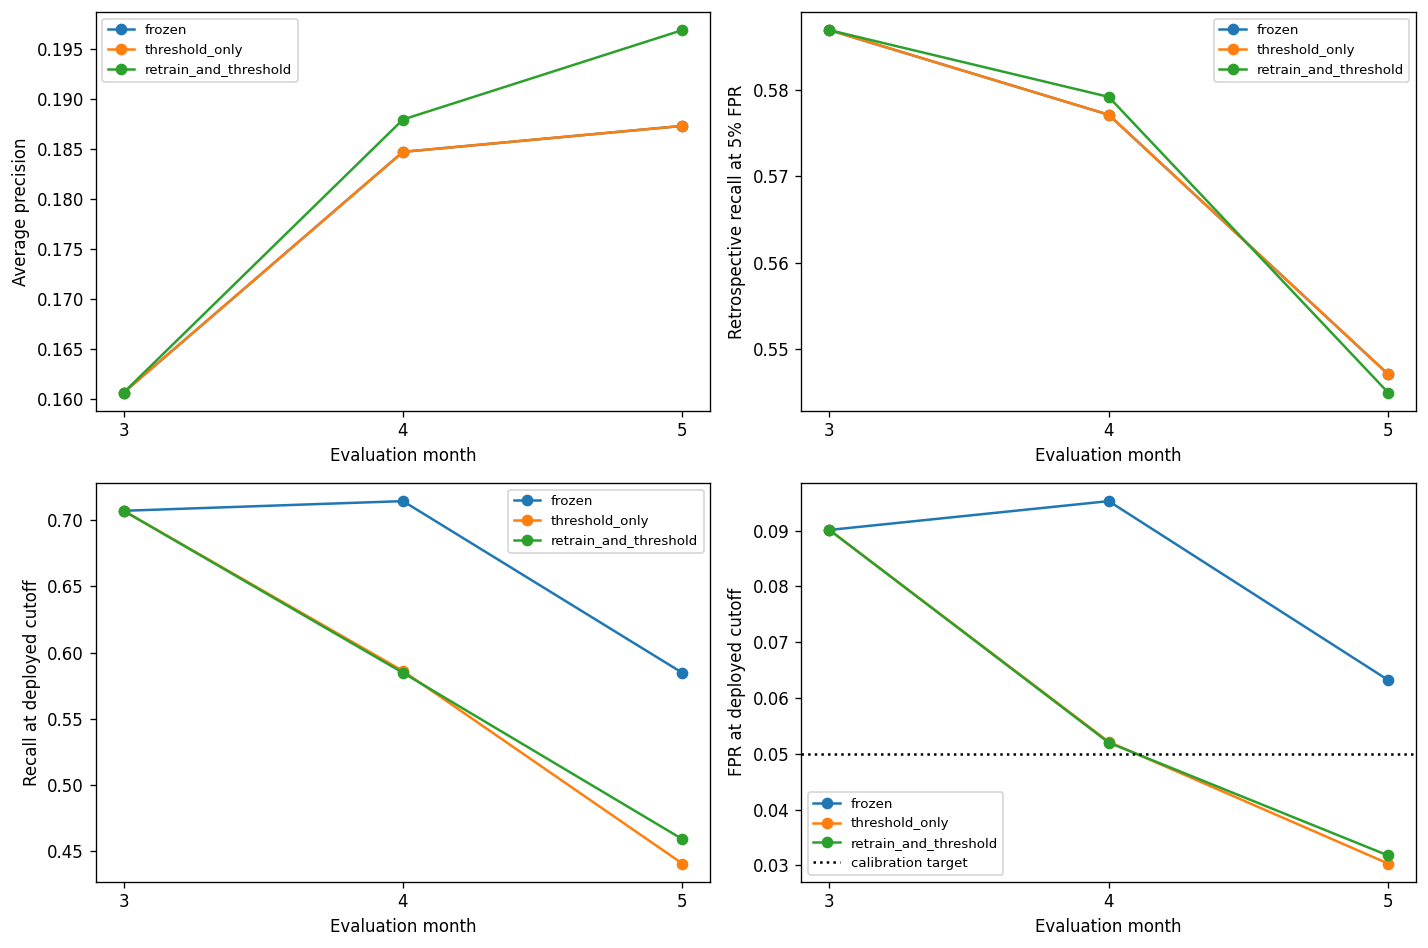

In [8]:
metrics = pd.DataFrame(metric_rows)
capacity = pd.DataFrame(capacity_rows)
assert len(fit_records) == 9 and len(metrics) == 9
ranking_columns = ['ap', 'roc_auc', 'retrospective_recall_at_5fpr']
for m in EVALUATION_MONTHS:
    part = metrics[metrics.evaluation_month.eq(m)].set_index('policy')
    assert np.allclose(part.loc['frozen', ranking_columns].astype(float),
                       part.loc['threshold_only', ranking_columns].astype(float))
first = metrics[metrics.evaluation_month.eq(EVALUATION_MONTHS[0])]
for col in ranking_columns + ['deployed_cutoff', 'deployed_recall', 'deployed_fpr']:
    assert np.allclose(first[col], first[col].iloc[0])

display(metrics[['evaluation_month', 'policy', 'ap', 'retrospective_recall_at_5fpr',
                 'deployed_recall', 'deployed_fpr', 'deployed_precision', 'deployed_alert_rate',
                 'deployed_tp', 'deployed_fp']])

delta_rows = []
for m in EVALUATION_MONTHS:
    part = metrics[metrics.evaluation_month.eq(m)].set_index('policy')
    for a, b, label in [
        ('threshold_only', 'frozen', 'threshold maintenance'),
        ('retrain_and_threshold', 'threshold_only', 'model refresh under same calibration policy'),
        ('retrain_and_threshold', 'frozen', 'overall update policy'),
    ]:
        delta_rows.append({'evaluation_month': m, 'comparison': label,
            **{col + '_difference': float(part.loc[a, col] - part.loc[b, col])
               for col in ['ap', 'retrospective_recall_at_5fpr', 'deployed_recall',
                           'deployed_fpr', 'deployed_tp', 'deployed_fp']}})
deltas = pd.DataFrame(delta_rows)
deltas.to_csv(RESULTS_DIR / 'monthly_policy_differences.csv', index=False)
display(deltas)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column, label in zip(axes.flat,
    ['ap', 'retrospective_recall_at_5fpr', 'deployed_recall', 'deployed_fpr'],
    ['Average precision', 'Retrospective recall at 5% FPR', 'Recall at deployed cutoff', 'FPR at deployed cutoff']):
    for policy in POLICIES:
        part = metrics[metrics.policy.eq(policy)]
        ax.plot(part.evaluation_month, part[column], marker='o', label=policy)
    if column == 'deployed_fpr':
        ax.axhline(FPR_TARGET, color='black', linestyle=':', label='calibration target')
    ax.set(xlabel='Evaluation month', ylabel=label, xticks=EVALUATION_MONTHS)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'monthly_policy_comparison.png')
plt.show()


## 8. Aggregate workload, capture and fitting cost

Sum the confusion counts from each month's deployed decisions, then calculate pooled precision, recall and FPR. Do not apply one newly optimised cutoff to concatenated scores: the refreshed model and cutoff can change each month.

Report both all three evaluation months and the update months (4–5), because month 3 is identical for all policies. These are descriptive policy summaries, not independent repeated trials. Mean monthly AP is a macro average, **not pooled AP**.

Exact-capacity results describe a separate monthly top-K queue policy, not the workload guaranteed by the FPR-calibrated cutoff. Frozen and threshold-only scores rank identically, so their exact-capacity results coincide.


In [9]:
aggregate_rows = []
for period, months_to_include in [('all_evaluation_months', [3, 4, 5]), ('update_months_only', [4, 5])]:
    for policy in POLICIES:
        part = metrics[metrics.policy.eq(policy) & metrics.evaluation_month.isin(months_to_include)]
        tp, fp, fn, tn = [int(part['deployed_' + k].sum()) for k in ['tp', 'fp', 'fn', 'tn']]
        total = tp + fp + fn + tn
        aggregate_rows.append({
            'period': period, 'policy': policy, 'applications': total,
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
            'pooled_recall': tp / (tp + fn), 'pooled_fpr': fp / (fp + tn),
            'pooled_precision': tp / (tp + fp) if tp + fp else 0.0,
            'review_fraction': (tp + fp) / total,
            'frauds_caught_per_10000': 10000 * tp / total,
            'legitimate_flagged_per_10000': 10000 * fp / total,
            'mean_monthly_ap': part.ap.mean(),
        })
aggregate = pd.DataFrame(aggregate_rows)
aggregate.to_csv(RESULTS_DIR / 'policy_aggregate.csv', index=False)
display(aggregate)

capacity_summary = capacity.groupby(['policy', 'capacity']).agg(
    reviews=('reviews', 'sum'), frauds_caught=('frauds_flagged', 'sum'),
    legitimate_reviewed=('legitimate_reviewed', 'sum'), frauds_missed=('frauds_missed', 'sum'),
).reset_index()
capacity_summary['pooled_precision'] = capacity_summary.frauds_caught / capacity_summary.reviews
capacity_summary['pooled_recall'] = capacity_summary.frauds_caught / (
    capacity_summary.frauds_caught + capacity_summary.frauds_missed)
capacity_summary.to_csv(RESULTS_DIR / 'capacity_aggregate.csv', index=False)
display(capacity_summary)

fits = pd.DataFrame(fit_records)
fit_cost = fits.groupby('origin').agg(fits=('seed', 'size'), fit_seconds=('fit_seconds', 'sum')).reset_index()
fit_cost.to_csv(RESULTS_DIR / 'fit_cost_by_origin.csv', index=False)
display(fit_cost)
print('Frozen and threshold-only: pay the initial 3-model fit once.')
print('Retraining policy: initial fit plus 6 further model fits over the two update months.')
print('Fit timing excludes calibration scoring, data preparation, storage and deployment overhead.')
run_info['status'] = 'complete'
run_info['fit_records'] = fit_records
write_json('run_manifest.json', run_info)
print('Saved results:', RESULTS_DIR)


,period,policy,applications,tp,fp,fn,tn,pooled_recall,pooled_fpr,pooled_precision,review_fraction,frauds_caught_per_10000,legitimate_flagged_per_10000,mean_monthly_ap
0,all_evaluation_months,frozen,397950,2846,32963,1409,360732,0.668860,0.083727,0.079477,0.089984,71.516522,828.320141,0.177563
1,all_evaluation_months,threshold_only,397950,2457,23636,1798,370059,0.577438,0.060036,0.094163,0.065569,61.741425,593.943963,0.177563
2,all_evaluation_months,retrain_and_threshold,397950,2481,23788,1774,369907,0.583079,0.060422,0.094446,0.066011,62.344516,597.763538,0.181834
3,update_months_only,frozen,247014,1862,19485,1001,224666,0.650367,0.079807,0.087225,0.086420,75.380343,788.821686,0.186017
4,update_months_only,threshold_only,247014,1473,10158,1390,233993,0.514495,0.041605,0.126644,0.047086,59.632248,411.231752,0.186017
5,update_months_only,retrain_and_threshold,247014,1497,10310,1366,233841,0.522878,0.042228,0.126789,0.047799,60.603852,417.385249,0.192422


,policy,capacity,reviews,frauds_caught,legitimate_reviewed,frauds_missed,pooled_precision,pooled_recall
0,frozen,0.01,3978,985,2993,3270,0.247612,0.231492
1,frozen,0.02,7957,1464,6493,2791,0.183989,0.344066
2,frozen,0.05,19896,2314,17582,1941,0.116305,0.543831
3,retrain_and_threshold,0.01,3978,1001,2977,3254,0.251634,0.235253
4,retrain_and_threshold,0.02,7957,1497,6460,2758,0.188136,0.351821
5,retrain_and_threshold,0.05,19896,2320,17576,1935,0.116606,0.545241
6,threshold_only,0.01,3978,985,2993,3270,0.247612,0.231492
7,threshold_only,0.02,7957,1464,6493,2791,0.183989,0.344066
8,threshold_only,0.05,19896,2314,17582,1941,0.116305,0.543831


,origin,fits,fit_seconds
0,3,3,84.514566
1,4,3,91.263444
2,5,3,123.673209


Frozen and threshold-only: pay the initial 3-model fit once.
Retraining policy: initial fit plus 6 further model fits over the two update months.
Fit timing excludes calibration scoring, data preparation, storage and deployment overhead.
Saved results: /content/drive/MyDrive/BT4012_grp_proj/results/monthly_retraining/20261117T155430Z_2496ed


## 9. Interpretation and further exploration

Use the run to answer:

1. Does the frozen cutoff's FPR change as the application population changes?
2. Does threshold recalibration bring future-month FPR closer to 5%, without assuming it guarantees that constraint?
3. Does retraining improve within-month AP, retrospective recall@5% FPR or exact review-budget capture beyond threshold-only updates?
4. Are gains consistent across months 4 and 5, or concentrated in one month?
5. Is the extra training and deployment overhead justified by the observed operational difference?

If only threshold updates help, model retraining may be less urgent under this simulation. If model refresh helps ranking as well, the findings motivate a retraining policy. If neither helps, report that outcome without treating it as proof that refreshing can never help.

**Limitations:** only two distinct update opportunities; previously selected hyperparameters used retrospectively; recent-month labels assumed immediately available; rolling calibration may itself be stale; increasing sample size and recency change together. This is a development study, not a causal experiment or a production deployment guarantee.

For later evaluation on months 6–7, declare the training, label-delay and calibration schedule in advance and document prior test exposure. Keep any follow-up protocol changes separate from this run.

**Share:** the executed notebook, `monthly_policy_metrics.csv`, `monthly_policy_differences.csv`, `policy_aggregate.csv`, `capacity_aggregate.csv`, `threshold_history.json` and `run_manifest.json`. Keep models, prediction parquet files and sampled row IDs outside ordinary Git commits.
